### Import libraries

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 

import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense
)

### Load the Dataset

In [20]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [21]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (60000, 28, 28)
y_train: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)


### Exploratory Data Analysis (EDA)

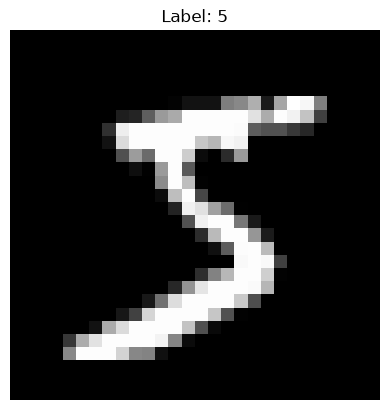

In [22]:
plt.imshow(X_train[0], cmap='gray')

plt.title(f"Label: {y_train[0]}")
plt.axis('off')

plt.show()

### Visualize multiple images

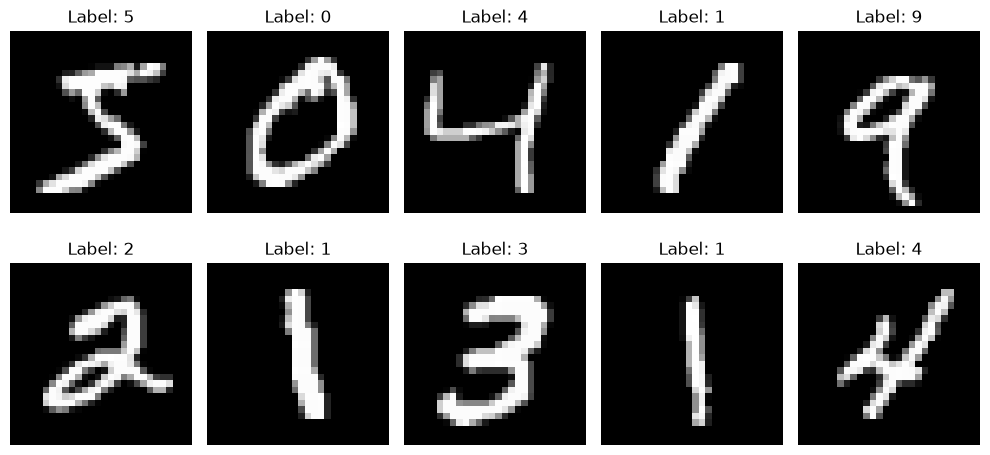

In [23]:
plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i], cmap='gray')

    plt.title(f"Label: {y_train[i]}")

    plt.axis('off')

plt.tight_layout()
plt.show()

### Data preprocessing

Normalization

In [24]:
X_train = X_train / 255.0
X_test = X_test / 255.0

Reshape the images

In [25]:
X_train = X_train.reshape(-1, 28, 28, 1)

X_test = X_test.reshape(-1, 28, 28, 1)

## Build the CNN architecture

In [26]:
# Initialize the CNN model Using Sequential API
model = Sequential()

### Add convolution layer

In [27]:
model.add(
    Conv2D(
        filters = 32,
        kernel_size = (3,3),
        activation = 'relu',
        input_shape = (28,28,1) 
    )
)

### Add Max Pooling

In [28]:
model.add(
    MaxPooling2D( pool_size=(2,2) )
)

### Add another convolution layer

In [29]:
model.add(
    Conv2D(
        filters = 64,
        kernel_size= (3,3),
        activation= 'relu'
    )
)

### Add another Pooling layer

In [30]:
model.add(
    MaxPooling2D(pool_size=(2, 2))
)

### Flattening

In [31]:
model.add(Flatten())

### Add Dense layers

In [32]:
model.add(
    Dense(64,activation='relu')
)

model.add(
    Dense(10,activation='softmax')
)

Check the architecture

In [33]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

### Compile the model

In [34]:
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Train the CNN

In [36]:
history = model.fit(
    X_train,
    y_train,
    epochs = 5,
    batch_size = 64,
    validation_split = 0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9882 - loss: 0.0369 - val_accuracy: 0.9890 - val_loss: 0.0408
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9906 - loss: 0.0282 - val_accuracy: 0.9922 - val_loss: 0.0357
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9929 - loss: 0.0221 - val_accuracy: 0.9892 - val_loss: 0.0458
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9947 - loss: 0.0168 - val_accuracy: 0.9888 - val_loss: 0.0441
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9956 - loss: 0.0134 - val_accuracy: 0.9920 - val_loss: 0.0371


### Evaluate the model

In [37]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9911 - loss: 0.0294
Test Loss: 0.029410317540168762
Test Accuracy: 0.991100013256073


### Make predictions
 
Predict one image

In [38]:
predictions = model.predict(X_test)

predicted_digit = np.argmax(predictions[0])

print("Predicted:", predicted_digit)
print("Actual:", y_test[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Predicted: 7
Actual: 7


### Visualize the prediction

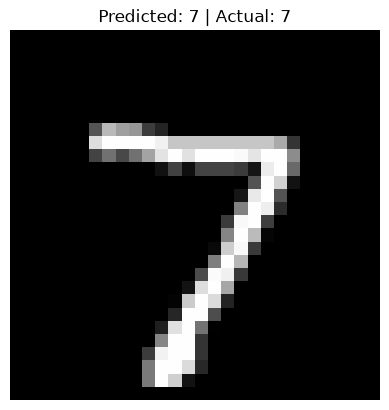

In [39]:
plt.imshow(X_test[0].reshape(28, 28), cmap='gray')

plt.title(
    f"Predicted: {predicted_digit} | Actual: {y_test[0]}"
)

plt.axis('off')
plt.show()

In [40]:
model.save("mnist_cnn_model.keras")